# Lab09: Decision Tree


## Decision Trees

**Decision tree learning** is a method for approximating discrete-valued or real-valued target functions, in which the learned function is represented as a **decision tree**. In this representation:

- each **internal node** tests one attribute of the instance;
- each **branch** leaving a node corresponds to one possible value (or range of values) of the tested attribute;
- each **leaf node** assigns a prediction, either a class label in classification or a numerical value in regression.

An instance is classified by starting at the root, following the branch that matches the instance's value for the tested attribute, and repeating this until a leaf is reached. The leaf's label is the prediction.

A decision tree can be rewritten as a set of **if-then rules**. Each path from the root to a leaf forms a **conjunction** (logical AND) of tests on attribute values, and the tree as a whole is the **disjunction** (logical OR) of these conjunctions. For example, a tree predicting whether to play tennis might encode

$$
(\text{Outlook} = \text{Sunny} \land \text{Humidity} = \text{Normal}) \;\lor\; (\text{Outlook} = \text{Overcast}) \;\lor\; (\text{Outlook} = \text{Rain} \land \text{Wind} = \text{Weak}),
$$

where each term in parentheses corresponds to one path ending in a "Yes" leaf.

![bias](images/DecisionTreeTreeExample.png)


Accuracy: 0.9777777777777777


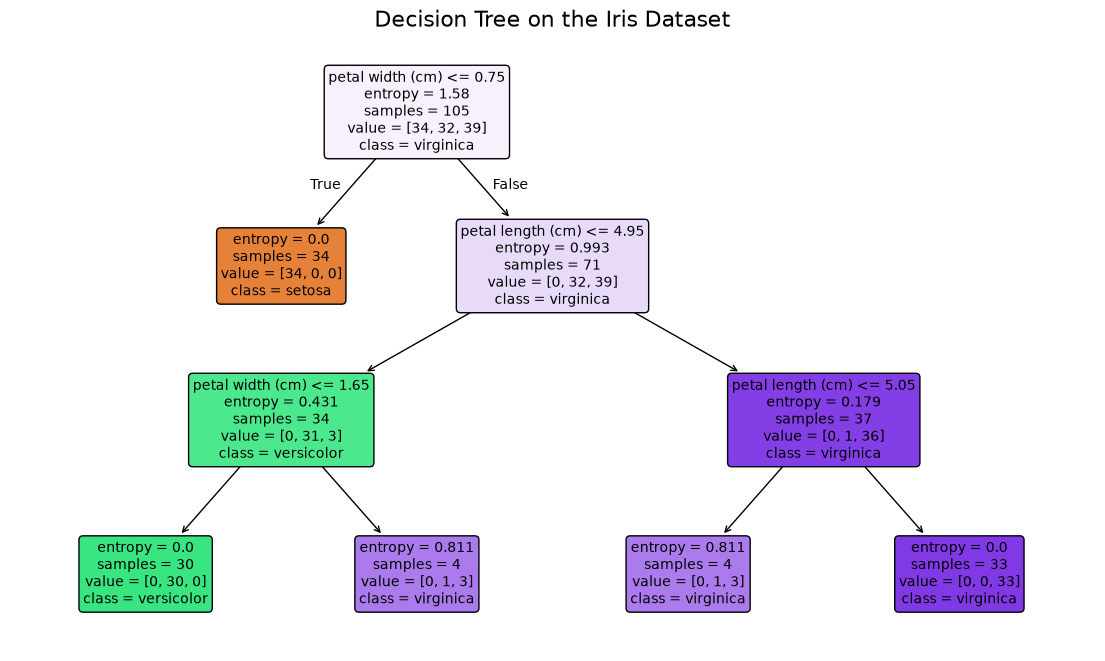

In [7]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.3, random_state=0)

model = DecisionTreeClassifier(criterion="entropy", max_depth=3)
model.fit(X_train, y_train)
print("Accuracy:", model.score(X_test, y_test))

plt.figure(figsize=(14, 8))
plot_tree(model, feature_names=iris.feature_names, class_names=iris.target_names,
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree on the Iris Dataset", fontsize=16)
plt.show()

## Top-Down Induction of Decision Trees (ID3)

The **ID3** algorithm builds a decision tree greedily from the root downward. It starts with a single root node containing all training examples and repeats the following steps for each node:

1. Select the **best** attribute $A$ for splitting the examples at the current node. This is the attribute that best separates the examples by class, usually measured by **information gain**.
2. Assign $A$ as the decision attribute of the node.
3. For each possible value of $A$, create a new child node.
4. Distribute the training examples among the child nodes according to their value of $A$.
5. If the examples at a child node are perfectly classified (all belong to the same class), make it a **leaf** labeled with that class. Otherwise, apply the procedure recursively to that child, considering only the attributes not already used on the path from the root.

The recursion also stops when no attributes remain to be tested. In that case, the node becomes a leaf labeled with the **majority class** among its examples.

## Decision Tree Algorithms


![bias](images/DecissionTreeAlgorithms.png)


## Choosing the Best Attribute for Splitting

![Comparison of candidate attributes for splitting](images/DecisionTreeAtrubutesChooseExample.png)

![Comparison of candidate attributes for splitting (continued)](images/DecisionTreeAtrubutesChooseExample2.png)

The key step of the ID3 algorithm is selecting the best attribute at each node. As the examples above illustrate, it is often difficult to judge by inspection which attribute separates the classes best. We therefore need a quantitative measure of how well an attribute splits the training examples. The two measures most commonly used for this purpose are **entropy**, which quantifies the impurity of a set of examples, and **information gain**, which measures how much a split on a given attribute reduces that impurity.


## Entropy

Let $S$ be a sample of training examples in a binary classification problem, and let $p_{+}$ and $p_{-}$ denote the proportions of positive and negative examples in $S$, so that $p_{+} + p_{-} = 1$. The **entropy** of $S$ measures its impurity, that is, the uncertainty about the class of an example drawn at random from $S$:

$$
H(S) = -p_{+} \log_2 p_{+} - p_{-} \log_2 p_{-},
$$

where, by convention, $0 \log_2 0 = 0$. Because the logarithm has base 2, entropy is measured in **bits**. It can be interpreted as the expected number of bits needed to encode the class of a randomly drawn example from $S$.

Entropy reaches its two extreme values in the following cases:

- $H(S) = 0$ when $S$ is **pure**, meaning all its examples belong to the same class. There is then no uncertainty about the class.
- $H(S) = 1$ bit when $S$ is **maximally impure**, with $p_{+} = p_{-} = 0.5$. Both classes are then equally likely.

For example, a sample with 9 positive and 5 negative examples has entropy

$$
H(S) = -\frac{9}{14} \log_2 \frac{9}{14} - \frac{5}{14} \log_2 \frac{5}{14} \approx 0.940 \text{ bits}.
$$

More generally, when there are $K$ classes with proportions $p_1, \ldots, p_K$, entropy is defined as

$$
H(S) = -\sum_{k=1}^{K} p_k \log_2 p_k,
$$

which attains its maximum value of $\log_2 K$ bits when all classes are equally represented.

#### Entropy of a Coin Flip

The entropy of a random variable with 2 outcomes has this entropy graph:

![CoinFlip Entropy](images/CoinFlipEntropy.png)

- $S_1$ is a **constant random variable**, since it takes a single value with probability $1$. Its outcome is certain, so the entropy is $0$.
- $S_2$ is a **Bernoulli random variable** with parameter $p = 0.75$ (or equivalently $0.25$, depending on which class is labeled positive), like a biased coin. The outcome is partially predictable, so the entropy lies strictly between $0$ and $1$.
- $S_3$ is a **Bernoulli random variable** with parameter $p = 0.5$, like a fair coin. Both outcomes are equally likely, which gives the maximum entropy of $1$ bit for two classes.

$
\begin{aligned}
H(S_1) &= -1 \times \log_2 1 - 0 \times \log_2 0 = 0 \\[4pt]
H(S_2) &= -0.75 \times \log_2 0.75 - 0.25 \times \log_2 0.25 \approx 0.811 \\[4pt]
H(S_3) &= -0.5 \times \log_2 0.5 - 0.5 \times \log_2 0.5 = 1
\end{aligned}
$

#### Entropy of a Dice
- $S$ is a **discrete uniform random variable** over $6$ values, like the roll of a fair die. All outcomes are equally likely, which gives the maximum entropy of $\log_2 6 \approx 2.585$ bits for six classes.

$
\begin{aligned}
H(S) &= -\frac{1}{6} \log_2 \frac{1}{6} - \frac{1}{6} \log_2 \frac{1}{6} - \frac{1}{6} \log_2 \frac{1}{6} - \frac{1}{6} \log_2 \frac{1}{6} - \frac{1}{6} \log_2 \frac{1}{6} - \frac{1}{6} \log_2 \frac{1}{6} \\[4pt]
&= -6 \times \frac{1}{6} \log_2 \frac{1}{6} = \log_2 6 \approx 2.585
\end{aligned}
$

## Information Gain

**Information gain** measures how much splitting a sample on a given attribute reduces its entropy. Let $S$ be a sample of training examples, $A$ an attribute, $\text{Values}(A)$ the set of possible values of $A$, and $S_v \subseteq S$ the subset of examples for which $A$ takes the value $v$. The information gain of $A$ with respect to $S$ is defined as

$$
\text{Gain}(S, A) = H(S) - \sum_{v \in \text{Values}(A)} \frac{|S_v|}{|S|} \, H(S_v).
$$

The first term is the entropy of $S$ before the split. The second term is the expected entropy after the split, computed as the average entropy of the subsets $S_v$, each weighted by the fraction of examples it contains. Information gain is therefore the **expected reduction in entropy** obtained by sorting the examples according to $A$. ID3 selects, at each node, the attribute with the highest information gain.

For example, consider a sample $S$ with 9 positive and 5 negative examples, so $H(S) \approx 0.940$, and an attribute $\text{Wind} \in \{\text{Weak}, \text{Strong}\}$. Suppose the 8 examples with weak wind contain 6 positive and 2 negative examples, so $H(S_{\text{Weak}}) \approx 0.811$. Suppose the 6 examples with strong wind contain 3 positive and 3 negative examples, so $H(S_{\text{Strong}}) = 1$. Then

$$
\text{Gain}(S, \text{Wind}) = 0.940 - \frac{8}{14} \times 0.811 - \frac{6}{14} \times 1 \approx 0.048.
$$

> **Remark.** Information gain is also known as the **mutual information** between the attribute $A$ and the class label $Y$. In this view, $H(S)$ corresponds to the entropy $H(Y)$, and the weighted sum corresponds to the conditional entropy $H(Y \mid A)$, so that $\text{Gain}(S, A) = I(Y; A) = H(Y) - H(Y \mid A)$.

## Steps of the ID3 Algorithm

The ID3 algorithm builds a decision tree by repeating the following steps at each node, starting from the root with the full training set:

1. Compute the entropy $H(S)$ of the current set of examples $S$ from its class distribution.
2. For each remaining attribute $A$:
   - split $S$ into subsets $S_v$, one for each value $v$ of $A$, and compute the entropy $H(S_v)$ of each subset;
   - combine these into the information gain $\text{Gain}(S, A)$, using the weighted average of the subset entropies.
3. Select the attribute with the highest information gain and make it the decision attribute of the current node.
4. Create one child node for each value of the selected attribute, and apply the same procedure **recursively** to each child, using its subset of examples and the remaining attributes.

The recursion stops when a node is pure, or when no attributes remain. In that case the node becomes a leaf labeled with the majority class.

### Pseudocode

```
def ID3(D, A):
    # D: set of training examples, A: set of available attributes
    if D is pure or A is empty:
        return Leaf(majority_class(D))

    A_best = argmax over a in A of InformationGain(D, a)
    root = Node(A_best)

    for v in values(A_best):
        D_v = subset of D where A_best == v
        if D_v is empty:
            child = Leaf(majority_class(D))
        else:
            child = ID3(D_v, A - {A_best})
        root.add_child(v, child)

    return root
```

## Geometric Interpretation

A decision tree can also be understood geometrically, as a partition of the feature space. Each internal node that tests a continuous feature against a threshold, such as $x_j \leq t$, divides the space with a line (in two dimensions) or a hyperplane (in higher dimensions) **perpendicular to the axis of feature** $x_j$. Each subsequent split further subdivides one of the resulting regions. As a result, the tree partitions the feature space into **axis-aligned rectangles**, with each region corresponding to one leaf. All points within a region receive the same prediction. For example, the root split $\text{petal width} \leq 0.75$ in the Iris tree corresponds to a vertical line that separates the setosa examples from the other two classes.

A consequence of this is that decision boundaries are always made up of axis-parallel segments. When the true boundary is diagonal, as in the two-cluster example used for logistic regression, a decision tree can only approximate it with a "staircase" of many small steps. A linear model can represent such a boundary exactly with a single line.

![CoinFlip Entropy](images/DecisionTreeVisualization.png)

![CoinFlip Entropy](images/DecisionTreeVisualization2.png)



## Bias Variance Tradeoff

![CoinFlip Entropy](images/OverVsUnderfitting.png)

![CoinFlip Entropy](images/BiasVsVariance.png)


## Common Techniques to Prevent Overfitting

- **Collecting more training data**
- **Cross-validation**
- **Reducing the number of features**
- **Pruning** (for decision trees)
- **Regularization**
  - Increasing the strength of the regularization term

## Techniques Specific to Decision Trees

- **Pruning**: limiting the size of the tree so that it does not fit noise in the training data.
  - **Pre-pruning**: stops growing the tree early, for example by limiting its maximum depth or requiring a minimum number of examples per leaf.
  - **Post-pruning**: grows the full tree first, then removes branches that do not improve performance on validation data.
- **Ensemble learning**: combining many trees into a single, more robust model.
  - **Random Forest**: trains many trees on random samples of the data and features, and averages their predictions (bagging).
  - **XGBoost**: trains trees sequentially, each one correcting the errors of the previous ones (gradient boosting).

## Ensemble Learning

**Ensemble learning** combines the predictions of several models, called **base learners**, into a single model that usually performs better than any of them individually. The underlying idea is that the errors of different models partly cancel out when their predictions are combined. The three main approaches differ in how the base learners are trained and combined.

### Bagging (Bootstrap Aggregating)

In **bagging**, $M$ models are trained **independently and in parallel**, each on a different **bootstrap sample**: a random sample of $n$ examples drawn with replacement from the training set. Their predictions are then combined, by majority vote for classification or by averaging for regression:

$$
\hat{f}(\mathbf{x}) = \frac{1}{M} \sum_{m=1}^{M} \hat{f}_m(\mathbf{x}).
$$

Averaging many models trained on slightly different data mainly **reduces variance**, which makes bagging well suited to unstable, high-variance learners such as deep decision trees. **Random Forest** extends bagging by also considering only a random subset of features at each split, which makes the individual trees less correlated.

### Boosting

In **boosting**, models are trained **sequentially**, with each new model focusing on the examples that the previous models handled poorly. In **AdaBoost**, this is done by increasing the weights of misclassified examples. In **gradient boosting**, each new model is fit to the residual errors of the current ensemble. The final prediction is a weighted combination of all models. Boosting mainly **reduces bias**, so it typically uses simple base learners, such as shallow trees. **XGBoost** is a widely used, highly optimized implementation of gradient boosting.

### Stacking

In **stacking** (stacked generalization), several base learners, often of different types such as a decision tree, k-NN, and logistic regression, are trained on the same data. A separate **meta-learner** is then trained to combine their predictions, using the base learners' outputs as its input features. To avoid overfitting, the meta-learner is trained on predictions the base learners made for data they were not trained on, typically obtained through cross-validation.

## Homework: ID3 Decision Tree for Breast Cancer Recurrence

## Objective

Implement the **ID3 decision tree classification algorithm** and apply it to the `breast-cancer.arff` dataset:

- [Breast Cancer — UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/breast+cancer)

## Missing Values

Some attributes contain the value `"?"`, which denotes a **missing value**. Handle these by filling them in with an approach of your choice, and **justify** why you chose it.

## Pruning

To prevent **overfitting**, use at least one **pre-pruning** approach and at least one **post-pruning** approach of your choice:

### 1. Pre-Pruning

- **N**: a constant defining the **maximum depth** of the tree.
- **K**: a constant defining the **minimum number of training examples** in a set (for a leaf).
- **G**: a constant defining the **minimum information gain**.

### 2. Post-Pruning

- **E**: error estimation (**Reduced Error Pruning**).
- **X**: the **χ² (chi-squared) test**.
- **C**: **Minimal Cost-Complexity Pruning**.

Each additional pruning approach implemented will count as a **bonus**.

## Data Splitting

To test the algorithm, **shuffle** the data and split it into training and test sets in an **80:20** ratio. The split must be **stratified**, so that the class proportions (201 no-recurrence, 85 recurrence) are preserved in the resulting training set, test set, and validation sets (from the cross-validation splits).

## Input

The program accepts one of three values:

- `0`: use only **pre-pruning**.
- `1`: use only **post-pruning**.
- `2`: use **both** types of pruning.

If more than one variant of a pruning approach is implemented, specific variants can be selected by adding the corresponding letters after the number. The pre-pruning variants are encoded as `N`, `K`, and `G`, and the post-pruning variants as `E`, `X`, and `C`.

- Input `0` means that **all** implemented pre-pruning variants are applied.
- Input `0 K` means that **only** the minimum-number-of-examples variant is applied.

The same logic applies to all other combinations.

## Output

The program should print:

1. **Train set accuracy**: the accuracy of the model trained and evaluated on the training set (standard split).
2. **10-fold cross-validation results**: the accuracy of each fold, together with the **average accuracy** and **standard deviation**, computed on the training set.
3. **Test set accuracy**: the accuracy of the model on the test set.

## Example

**Input:**

```
0
```

**Output:**

```
1. Train Set Accuracy:
    Accuracy: 70.90%

10-Fold Cross-Validation Results:

    Accuracy Fold 1: 71.00%
    Accuracy Fold 2: 69.72%
    Accuracy Fold 3: 71.30%
    Accuracy Fold 4: 73.05%
    Accuracy Fold 5: 69.53%
    Accuracy Fold 6: 69.53%
    Accuracy Fold 7: 73.16%
    Accuracy Fold 8: 71.53%
    Accuracy Fold 9: 69.06%
    Accuracy Fold 10: 71.09%

    Average Accuracy: 70.90%
    Standard Deviation: 1.37%

2. Test Set Accuracy:
    Accuracy: 69.07%
```